In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## learning-curve

**Validation accuracy on CIFAR-100 over training for our augmentation, Mixup and the baseline.** Lines show the mean and shaded bands ±1 std over 5 seeds; dashed lines mark the final mean accuracies of ours and Mixup (baseline: 87.8%). Ours converges to 91.2% final accuracy, 1.7 points above Mixup and 3.5 points above the baseline, and every seed of ours ends above every seed of both.

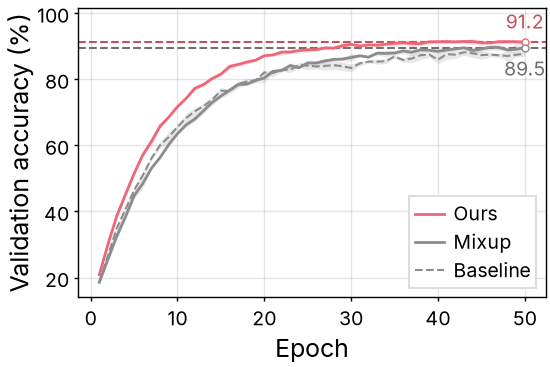

In [2]:
data = json.load(open("../data/learning-curve.json"))
epochs = data["epochs"]

fig, ax = plt.subplots(figsize=(2.75, 2))
series = [
    ("Ours", colors["ours"], "-"),
    ("Mixup", colors["neutral"], "-"),
    ("Baseline", colors["neutral"], "--"),
]
for name, color, linestyle in series:
    runs = 100 * np.array(data["accuracy"][name])
    mean, std = runs.mean(axis=0), runs.std(axis=0)
    linewidth = None if linestyle == "-" else paper.dashed_width
    ax.plot(epochs, mean, linestyle=linestyle, linewidth=linewidth, color=color, label=name)
    ax.fill_between(epochs, mean - std, mean + std, color=color, alpha=0.2, linewidth=0)
    if name != "Baseline":
        mark_value(ax, epochs[-1], mean[-1], f"{mean[-1]:#.3g}", color, below=name == "Mixup")

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy (%)")
ax.legend(loc="lower right")
fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/learning-curve.pdf")
fig.savefig("../outputs/learning-curve.png")
plt.show()